# Mineração de Dados — A2: Modelagem preditiva (UCMF)

**Objetivo:** prever `NORMAL X ANORMAL` (patologia cardíaca em crianças e jovens) **sem o atributo Sopro**.

**Regras do notebook**
- Cada pessoa edita **só a sua seção** (4, 5 ou 6). As seções 0 a 3 e 7 são compartilhadas.
- Todos os modelos usam **a mesma divisão treino/teste**, **o mesmo pré-processamento** e **a mesma função de avaliação** (seções 2 e 3). Não criem divisões nem validações próprias.
- O **conjunto de teste só é usado uma vez**, na seção 7, depois que os três modelos estiverem ajustados.
- Todas as transformações ficam **dentro do pipeline**, para serem ajustadas só nos dados de treino de cada fold (evita vazamento).
- Antes de entregar: *Ambiente de execução → Reiniciar e executar tudo*, para garantir que o código é reprodutível.

## 0. Configuração e leitura dos dados

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

SEED = 42          # fixo em tudo: divisão, folds e modelos (reprodutibilidade)
np.random.seed(SEED)

In [ ]:
CAMINHO = 'https://raw.githubusercontent.com/hyvo442/mineracao-ucmf/main/UCMF_limpo.csv'

df = pd.read_csv(CAMINHO)
print(df.shape)
PASTA = ''   # figuras salvas na pasta da sessão
df.head()

(11402, 22)


,ID,Peso,Altura,IMC,Atendimento,DN,IDADE,Convenio,PULSOS,PA SISTOLICA,PA DIASTOLICA,PPA,NORMAL X ANORMAL,B2,SOPRO,FC,HDA 1,HDA2,SEXO,MOTIVO1,MOTIVO2,FC_AUSENTE
0,1,5.0,51.0,19.2,2006-05-11,2006-03-30,0.114990,GS,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Sistólico,112.0,Palpitação,Nenhum,M,6 - Suspeita de cardiopatia,6 - Palpitação/taquicardia/arritmia,0
1,2,3.5,50.0,14.0,2005-05-25,2005-05-19,0.016427,GS,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Ausente,128.0,Dispneia,Nenhum,M,6 - Suspeita de cardiopatia,6 - Dispnéia,0
2,3,NaN,NaN,NaN,2001-06-12,NaN,NaN,SULA,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Sistólico,88.0,Assintomático,Nenhum,M,2 - Check-up,Sem subcategoria,0
3,4,8.1,65.0,19.2,2009-10-15,2009-04-21,0.484600,NaN,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Ausente,92.0,Assintomático,Nenhum,M,5 - Parecer cardiológico,Não informado,0
4,7,40.0,151.0,17.5,2008-01-14,1995-08-14,12.418891,SAME,Normais,NaN,NaN,Não Calculado,Anormal,Normal,Ausente,96.0,Dor precordial,Nenhum,M,5 - Parecer cardiológico,Não informado,0


## 1. Seleção de variáveis (decisões do grupo)
- **Sopro:** removido, conforme o enunciado (vazamento de informação: V de Cramér = 0,84 na A1).
- **ID, Atendimento e DN:** identificador e datas; a idade já resume a informação das datas.
- **Convênio:** atributo administrativo, sem relação clínica com o diagnóstico.
- **FC_AUSENTE:** removido porque o pipeline recria os indicadores de ausência de todas as numéricas.
- **MOTIVO2:** a categoria `6 - Sopro` reintroduz a informação do sopro (2.349 pacientes, 76% Anormal). Escolher a opção em `TRATAR_MOTIVO2`.
- **PPA:** classes agrupadas em Normal / Pré-hipertensão / Hipertensão / Não informado (o recálculo pelas tabelas ficou como limitação).

In [ ]:
import re, unicodedata

ALVO = 'NORMAL X ANORMAL'
REMOVER = ['SOPRO', 'ID', 'Atendimento', 'DN', 'Convenio', 'FC_AUSENTE']

# Opções: 'recodificar' ('6 - Sopro' vira 'Sem subcategoria'), 'remover' (tira a coluna inteira) ou 'manter'
TRATAR_MOTIVO2 = 'remover'       # <- DECISÃO DO GRUPO ('recodificar' ainda vaza o sopro, ver tabela acima)

SINTOMAS = ['Cianose', 'Desmaio/tontura', 'Dispneia', 'Dor precordial', 'Ganho de peso', 'Outro', 'Palpitação']


def nome_coluna(prefixo, rotulo):
    """'Desmaio/tontura' -> 'HDA_DESMAIO_TONTURA' (sem acentos nem símbolos)."""
    rotulo = unicodedata.normalize('NFKD', str(rotulo)).encode('ascii', 'ignore').decode()
    return prefixo + '_' + re.sub(r'[^0-9a-zA-Z]+', '_', rotulo).strip('_').upper()


def agrupar_ppa(v):
    """Agrupa a PPA em classes clínicas; 'Não Calculado' e vazio viram 'Não informado'."""
    if pd.isna(v) or v == 'Não Calculado':
        return 'Não informado'
    if v == 'Normal':
        return 'Normal'
    if 'Pre-Hipertens' in v:
        return 'Pré-hipertensão'
    return 'Hipertensão'


def codificar_hda(hda1, hda2):
    """HDA 1 + HDA2 -> uma coluna 0/1 por sintoma, anamnese não informada e nº de sintomas."""
    hda = pd.DataFrame({nome_coluna('HDA', s): ((hda1 == s) | (hda2 == s)).astype(int) for s in SINTOMAS},
                       index=hda1.index)
    hda['HDA_NAO_INFORMADO'] = (hda1 == 'Não informado').astype(int)
    hda['HDA_N_SINTOMAS'] = hda[[nome_coluna('HDA', s) for s in SINTOMAS]].sum(axis=1)
    return hda


def preparar_dados(df, tratar_motivo2=TRATAR_MOTIVO2):
    """Seleção de variáveis e transformações linha a linha (não aprendem nada com os dados)."""
    d = df.drop(columns=[c for c in REMOVER if c in df.columns]).copy()
    if tratar_motivo2 == 'recodificar':
        d['MOTIVO2'] = d['MOTIVO2'].replace({'6 - Sopro': 'Sem subcategoria'})
    elif tratar_motivo2 == 'remover':
        d = d.drop(columns='MOTIVO2')
    d['PPA'] = d['PPA'].map(agrupar_ppa)
    d['PULSOS'] = d['PULSOS'].replace({'Femorais diminuídos': 'Diminuídos'})
    d = d.drop(columns=['HDA 1', 'HDA2']).join(codificar_hda(d['HDA 1'], d['HDA2']))
    return d


dados = preparar_dados(df)
assert not any('SOPRO' in c.upper() for c in dados.columns), 'Sopro não pode entrar no modelo'
if 'MOTIVO2' in dados:
    assert (dados['MOTIVO2'] != '6 - Sopro').all()

print(dados.shape)
print('Variáveis usadas:', [c for c in dados.columns if c != ALVO])
print(dados['PPA'].value_counts())

(11402, 22)
Variáveis usadas: ['Peso', 'Altura', 'IMC', 'IDADE', 'PULSOS', 'PA SISTOLICA', 'PA DIASTOLICA', 'PPA', 'B2', 'FC', 'SEXO', 'MOTIVO1', 'HDA_CIANOSE', 'HDA_DESMAIO_TONTURA', 'HDA_DISPNEIA', 'HDA_DOR_PRECORDIAL', 'HDA_GANHO_DE_PESO', 'HDA_OUTRO', 'HDA_PALPITACAO', 'HDA_NAO_INFORMADO', 'HDA_N_SINTOMAS']
PPA
Não informado      9341
Normal             1780
Hipertensão         162
Pré-hipertensão     119
Name: count, dtype: int64


## 2. Divisão treino/teste e pré-processamento (Pessoa 1)
- Divisão **80/20 estratificada** pelo alvo (mantém a proporção de Anormal nos dois conjuntos).
- **Numéricas:** ausente preenchido pela mediana **do treino** + indicador de ausência (a ausência pode ser informativa, como visto na A1) + padronização (z-score).
- **Categóricas:** ausente vira a categoria `Não informado` + one-hot.
- Tudo dentro de um `Pipeline`, então é reajustado em cada fold da validação cruzada.

In [ ]:
y = (dados[ALVO] == 'Anormal').astype(int)      # 1 = Anormal (classe positiva)
X = dados.drop(columns=ALVO)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

MEDIDAS = ['Peso', 'Altura', 'IMC', 'PA SISTOLICA', 'PA DIASTOLICA', 'FC']
MEDIDAS_POR_SEXO = ['Peso', 'Altura', 'IMC', 'PA SISTOLICA', 'PA DIASTOLICA']   # FC: referência só por idade
CATEGORICAS = ['SEXO', 'PPA', 'PULSOS', 'B2', 'MOTIVO1'] + (['MOTIVO2'] if 'MOTIVO2' in X else [])
BINARIAS = [c for c in X.columns if c.startswith('HDA_')]

usadas = set(MEDIDAS) | {'IDADE'} | set(CATEGORICAS) | set(BINARIAS)
assert usadas == set(X.columns), f'Colunas sem tratamento: {set(X.columns) - usadas}'

print(f'Treino: {X_treino.shape} | Teste: {X_teste.shape}')
print(f'% Anormal -> treino: {y_treino.mean():.1%} | teste: {y_teste.mean():.1%}')
print('Medidas (z-score por idade):', MEDIDAS)
print('Categóricas (one-hot):', CATEGORICAS)
print('Binárias (HDA):', BINARIAS)

Treino: (9121, 21) | Teste: (2281, 21)
% Anormal -> treino: 42.6% | teste: 42.7%
Medidas (z-score por idade): ['Peso', 'Altura', 'IMC', 'PA SISTOLICA', 'PA DIASTOLICA', 'FC']
Categóricas (one-hot): ['SEXO', 'PPA', 'PULSOS', 'B2', 'MOTIVO1']
Binárias (HDA): ['HDA_CIANOSE', 'HDA_DESMAIO_TONTURA', 'HDA_DISPNEIA', 'HDA_DOR_PRECORDIAL', 'HDA_GANHO_DE_PESO', 'HDA_OUTRO', 'HDA_PALPITACAO', 'HDA_NAO_INFORMADO', 'HDA_N_SINTOMAS']


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

FAIXAS_IDADE = [0, 1, 3, 6, 13, 20]   # <1, 1-2, 3-5, 6-12 e 13-19 anos (as mesmas da A1)


class ZScorePorIdade(BaseEstimator, TransformerMixin):
    """Converte cada medida em z-score dentro da faixa etária (e do sexo, para as medidas em `por_sexo`).
    fit: aprende média e desvio de cada grupo SÓ nos dados recebidos (treino do fold).
         Grupos faixa x sexo com menos de `min_grupo` casos usam a média/desvio só da faixa.
    transform: z = (valor - média do grupo) / desvio do grupo. Medida ou idade ausente -> NaN.
    Entrada: DataFrame com IDADE, SEXO e as medidas. Saída: uma coluna <MEDIDA>_Z_IDADE por medida.
    """

    def __init__(self, medidas, por_sexo=(), min_grupo=30):
        self.medidas = medidas
        self.por_sexo = por_sexo
        self.min_grupo = min_grupo

    def _faixa(self, X):
        return pd.cut(X['IDADE'], FAIXAS_IDADE, right=False, labels=False)

    def fit(self, X, y=None):
        faixa = self._faixa(X)
        self.por_faixa_, self.por_faixa_sexo_ = {}, {}
        for m in self.medidas:
            self.por_faixa_[m] = X[m].groupby(faixa).agg(['mean', 'std'])
            if m in self.por_sexo:
                g = X[m].groupby([faixa, X['SEXO']]).agg(['mean', 'std', 'count'])
                self.por_faixa_sexo_[m] = g[g['count'] >= self.min_grupo]
        return self

    def transform(self, X):
        faixa = self._faixa(X)
        saida = np.empty((len(X), len(self.medidas)))
        for j, m in enumerate(self.medidas):
            media = faixa.map(self.por_faixa_[m]['mean'])
            desvio = faixa.map(self.por_faixa_[m]['std'])
            if m in self.por_faixa_sexo_:
                chave = pd.MultiIndex.from_arrays([faixa, X['SEXO']])
                g = self.por_faixa_sexo_[m]
                media_s = pd.Series(g['mean'].reindex(chave).values, index=X.index)
                desvio_s = pd.Series(g['std'].reindex(chave).values, index=X.index)
                tem_grupo = media_s.notna()
                media, desvio = media.mask(tem_grupo, media_s), desvio.mask(tem_grupo, desvio_s)
            saida[:, j] = ((X[m] - media) / desvio).to_numpy(dtype=float)
        return saida

    def get_feature_names_out(self, input_features=None):
        nomes = {'PA SISTOLICA': 'PAS', 'PA DIASTOLICA': 'PAD'}
        return np.array([f"{nomes.get(m, m).upper()}_Z_IDADE" for m in self.medidas], dtype=object)

In [ ]:
MIN_FREQ = 20   # categorias com menos casos que isso no treino viram uma categoria "rara"


def criar_preprocessador():
    """Pré-processamento comum a todos os modelos (ajustado só no treino de cada fold)."""
    medidas = Pipeline([
        ('z_idade', ZScorePorIdade(MEDIDAS, por_sexo=MEDIDAS_POR_SEXO)),
        ('imputar', SimpleImputer(strategy='constant', fill_value=0, add_indicator=True)),   # 0 = típico p/ idade
    ])
    idade = Pipeline([
        ('imputar', SimpleImputer(strategy='median', add_indicator=True)),
        ('padronizar', StandardScaler()),
    ])
    categoricas = Pipeline([
        ('imputar', SimpleImputer(strategy='constant', fill_value='Não informado')),
        ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=MIN_FREQ,
                                 sparse_output=False)),
    ])
    return ColumnTransformer([
        ('med', medidas, ['IDADE', 'SEXO'] + MEDIDAS),
        ('idade', idade, ['IDADE']),
        ('cat', categoricas, CATEGORICAS),
        ('hda', 'passthrough', BINARIAS),
    ], verbose_feature_names_out=False)


def criar_pipeline(modelo):
    return Pipeline([('prep', criar_preprocessador()), ('modelo', modelo)])


# Conferência: ajusta o pré-processamento no treino e mostra as colunas que os modelos recebem
prep = criar_preprocessador().fit(X_treino, y_treino)
Xt = pd.DataFrame(prep.transform(X_treino), columns=prep.get_feature_names_out(), index=X_treino.index)

## 3. Protocolo de avaliação comum (Pessoa 1)
- **Validação cruzada estratificada com 10 folds**, sempre as mesmas partições (`SEED` fixo).
- **Métricas:** recall, precisão, F1, acurácia balanceada e ROC-AUC. O **recall da classe Anormal** é o mais importante no contexto: um falso negativo é uma criança doente não detectada.
- **Ajuste de hiperparâmetros** com `GridSearchCV`, só no treino, otimizando `METRICA_AJUSTE`.

In [ ]:
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
METRICAS = {'recall': 'recall', 'precisao': 'precision', 'f1': 'f1',
            'acuracia_bal': 'balanced_accuracy', 'roc_auc': 'roc_auc'}
METRICA_AJUSTE = 'f1'   # métrica usada para escolher os hiperparâmetros (temporário p/ enquanto)

resultados_cv = {}      # desempenho de cada modelo na validação cruzada (média e desvio dos 10 folds)
modelos_finais = {}     # melhor pipeline de cada modelo, ajustado em todo o treino


def guardar_resultado(nome, medias, desvios, pipeline, final=True):
    """Registra o desempenho (e, se final=True, o pipeline que vai para o teste) e mostra 'média ± desvio'."""
    res = {m: medias[m] for m in METRICAS}
    res.update({f'{m}_dp': desvios[m] for m in METRICAS})
    resultados_cv[nome] = res
    if final:
        modelos_finais[nome] = pipeline
    display(pd.DataFrame({m: [f"{res[m]:.3f} ± {res[m + '_dp']:.3f}"] for m in METRICAS}, index=[nome]))
    return res


def avaliar_modelo(nome, modelo, final=True):
    """Validação cruzada (10 folds estratificados) de um modelo com hiperparâmetros fixos."""
    pipeline = criar_pipeline(modelo)
    cv = cross_validate(pipeline, X_treino, y_treino, cv=CV, scoring=METRICAS, n_jobs=-1)
    medias = {m: cv[f'test_{m}'].mean() for m in METRICAS}
    desvios = {m: cv[f'test_{m}'].std() for m in METRICAS}
    pipeline.fit(X_treino, y_treino)
    return guardar_resultado(nome, medias, desvios, pipeline, final)


def ajustar_modelo(nome, modelo, grade):
    """Ajusta os hiperparâmetros com GridSearchCV (mesmos folds e métricas para todos) e guarda o resultado."""
    busca = GridSearchCV(criar_pipeline(modelo), grade, cv=CV, scoring=METRICAS,
                         refit=METRICA_AJUSTE, n_jobs=-1)
    busca.fit(X_treino, y_treino)
    i = busca.best_index_
    medias = {m: busca.cv_results_[f'mean_test_{m}'][i] for m in METRICAS}
    desvios = {m: busca.cv_results_[f'std_test_{m}'][i] for m in METRICAS}
    print(f'{nome} | melhores hiperparâmetros: {busca.best_params_}')
    guardar_resultado(nome, medias, desvios, busca.best_estimator_)
    return busca


## 4. Regressão logística — baseline (Pessoa 1)
Modelo linear e interpretável, usado como referência mínima de desempenho.

In [ ]:
grade_lr = {
    'modelo__C': [0.01, 0.1, 1, 10],          # força da regularização (menor = mais regularizado)
    'modelo__class_weight': [None, 'balanced'],
}
busca_lr = ajustar_modelo('Regressão logística',
                          LogisticRegression(max_iter=2000, random_state=SEED), grade_lr)

# Resultado de todas as combinações da grade (ajuda a justificar a escolha no artigo)
grade_tab = pd.DataFrame(busca_lr.cv_results_['params'])
for m in METRICAS:
    grade_tab[m] = busca_lr.cv_results_[f'mean_test_{m}']
display(grade_tab.sort_values(METRICA_AJUSTE, ascending=False).round(3))

Regressão logística | melhores hiperparâmetros: {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'}


,recall,precisao,f1,acuracia_bal,roc_auc
Regressão logística,0.654 ± 0.016,0.660 ± 0.022,0.657 ± 0.018,0.702 ± 0.016,0.760 ± 0.016


,modelo__C,modelo__class_weight,recall,precisao,f1,acuracia_bal,roc_auc
3,0.10,balanced,0.654,0.660,0.657,0.702,0.760
7,10.00,balanced,0.647,0.664,0.655,0.701,0.760
1,0.01,balanced,0.669,0.642,0.655,0.696,0.755
5,1.00,balanced,0.647,0.663,0.655,0.701,0.760
6,10.00,None,0.576,0.717,0.639,0.703,0.760
2,0.10,None,0.578,0.714,0.639,0.703,0.760
4,1.00,None,0.576,0.715,0.638,0.703,0.760
0,0.01,None,0.578,0.703,0.634,0.698,0.755


,coeficiente,razao_de_chances
B2_Normal,-1.642,0.194
MOTIVO1_1 - Cardiopatia já estabelecida,0.901,2.463
B2_Hiperfonética,0.899,2.457
HDA_NAO_INFORMADO,-0.857,0.424
MOTIVO1_5 - Parecer cardiológico,-0.827,0.437
MOTIVO1_2 - Check-up,-0.648,0.523
MOTIVO1_6 - Suspeita de cardiopatia,0.611,1.841
PULSOS_Normais,-0.527,0.590
HDA_PALPITACAO,-0.523,0.593
PULSOS_Diminuídos,0.471,1.601


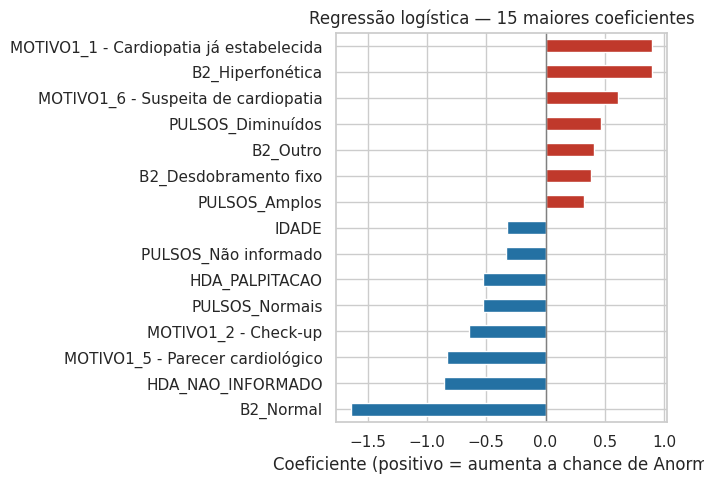

In [ ]:
# Interpretação: coeficientes da regressão logística (as entradas estão na mesma escala)
lr = modelos_finais['Regressão logística']
coeficientes = pd.DataFrame({
    'coeficiente': lr['modelo'].coef_[0],
    'razao_de_chances': np.exp(lr['modelo'].coef_[0]),   # >1 aumenta a chance de Anormal; <1 diminui
}, index=lr['prep'].get_feature_names_out())
coeficientes = coeficientes.reindex(coeficientes['coeficiente'].abs().sort_values(ascending=False).index)
display(coeficientes.head(15).round(3))

top = coeficientes.head(15)['coeficiente'].sort_values()
top.plot.barh(figsize=(7, 5), color=np.where(top > 0, '#c0392b', '#2471a3'))
plt.axvline(0, color='grey', lw=1)
plt.xlabel('Coeficiente (positivo = aumenta a chance de Anormal)')
plt.title('Regressão logística — 15 maiores coeficientes')
plt.tight_layout()
plt.savefig(PASTA + 'fig_coeficientes_lr.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Random Forest (Pessoa 2)
Conjunto de árvores de decisão treinadas em amostras diferentes; captura relações não lineares e interações.
Ajustem a grade abaixo (cuidado: grades grandes com 10 folds demoram).

In [ ]:
# 5.1 Referência: Random Forest com hiperparâmetros padrão (sem ajuste)
_ = avaliar_modelo('RF padrão', RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
               final=False)   # final=False: não vai para a seção 7, serve só de comparação

,recall,precisao,f1,acuracia_bal,roc_auc
RF padrão,0.589 ± 0.022,0.688 ± 0.024,0.635 ± 0.021,0.695 ± 0.017,0.762 ± 0.020


In [ ]:
# 5.2 Ajuste de hiperparâmetros
grade_rf = {
    'modelo__n_estimators': [200, 400],
    'modelo__max_depth': [None, 10, 20],
    'modelo__max_features': ['sqrt', 0.3, 0.5],     # nº de variáveis sorteadas em cada divisão
    'modelo__min_samples_leaf': [5, 10, 20],        # 5 venceu na borda da grade anterior ([1, 5])
    'modelo__class_weight': [None, 'balanced'],
}
busca_rf = ajustar_modelo('Random Forest',
                          RandomForestClassifier(random_state=SEED, n_jobs=1), grade_rf)

# Resultado de todas as combinações (para justificar a escolha no artigo)
grade_tab_rf = pd.DataFrame(busca_rf.cv_results_['params'])
for m in METRICAS:
    grade_tab_rf[m] = busca_rf.cv_results_[f'mean_test_{m}']
display(grade_tab_rf.sort_values(METRICA_AJUSTE, ascending=False).round(3))

Random Forest | melhores hiperparâmetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 400}


,recall,precisao,f1,acuracia_bal,roc_auc
Random Forest,0.652 ± 0.020,0.679 ± 0.026,0.665 ± 0.021,0.711 ± 0.018,0.776 ± 0.020


,modelo__class_weight,modelo__max_depth,modelo__max_features,modelo__min_samples_leaf,modelo__n_estimators,recall,precisao,f1,acuracia_bal,roc_auc
57,balanced,NaN,sqrt,10,400,0.652,0.679,0.665,0.711,0.776
56,balanced,NaN,sqrt,10,200,0.651,0.678,0.664,0.710,0.776
94,balanced,20.0,sqrt,20,200,0.658,0.671,0.664,0.709,0.773
58,balanced,NaN,sqrt,20,200,0.658,0.671,0.664,0.709,0.773
91,balanced,20.0,sqrt,5,400,0.644,0.685,0.664,0.712,0.777
...,...,...,...,...,...,...,...,...,...,...
42,None,20.0,0.3,5,200,0.590,0.708,0.643,0.704,0.776
33,None,10.0,0.5,10,400,0.582,0.719,0.643,0.706,0.777
32,None,10.0,0.5,10,200,0.582,0.718,0.643,0.706,0.777
25,None,10.0,0.3,5,400,0.581,0.719,0.643,0.706,0.778


## 6. Gradient Boosting (Pessoa 3)
Árvores treinadas em sequência, cada uma corrigindo os erros da anterior. Usamos a versão `HistGradientBoosting`, mais rápida.
Ajustem a grade abaixo.

6.1 Gradient Boosting com hiperparâmetros padrão (sem ajuste)

In [ ]:
avaliar_modelo('GB padrão', HistGradientBoostingClassifier(random_state=SEED),
               final=False)

,recall,precisao,f1,acuracia_bal,roc_auc
GB padrão,0.591 ± 0.017,0.716 ± 0.021,0.647 ± 0.017,0.708 ± 0.014,0.775 ± 0.020


{'recall': np.float64(0.5908998754405957),
 'precisao': np.float64(0.7161459024747809),
 'f1': np.float64(0.6474147872671351),
 'acuracia_bal': np.float64(0.7082965872612609),
 'roc_auc': np.float64(0.7752803407783844),
 'recall_dp': np.float64(0.016930862454945395),
 'precisao_dp': np.float64(0.021428136463936605),
 'f1_dp': np.float64(0.016942366332545804),
 'acuracia_bal_dp': np.float64(0.01358585709900867),
 'roc_auc_dp': np.float64(0.020225532690360246)}

6.2 Ajuste de hiperparâmetros (GridSearchCV)

In [ ]:
grade_gb = {
    'modelo__learning_rate': [0.03, 0.05, 0.1],
    'modelo__max_iter': [200, 300],
    'modelo__max_depth': [3, 5, None],
    'modelo__min_samples_leaf': [20, 50],
    'modelo__l2_regularization': [0.0, 1.0],
    'modelo__class_weight': [None, 'balanced'],
}

busca_gb = ajustar_modelo('Gradient Boosting',
                          HistGradientBoostingClassifier(random_state=SEED), grade_gb)

# Resultado de todas as combinações (para justificar a escolha no artigo)
grade_tab_gb = pd.DataFrame(busca_gb.cv_results_['params'])
for m in METRICAS:
    grade_tab_gb[m] = busca_gb.cv_results_[f'mean_test_{m}']
display(grade_tab_gb.sort_values(METRICA_AJUSTE, ascending=False).head(10).round(3))

Gradient Boosting | melhores hiperparâmetros: {'modelo__class_weight': 'balanced', 'modelo__l2_regularization': 1.0, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 5, 'modelo__max_iter': 300, 'modelo__min_samples_leaf': 50}


,recall,precisao,f1,acuracia_bal,roc_auc
Gradient Boosting,0.662 ± 0.020,0.680 ± 0.025,0.671 ± 0.020,0.715 ± 0.018,0.775 ± 0.019


,modelo__class_weight,modelo__l2_regularization,modelo__learning_rate,modelo__max_depth,modelo__max_iter,modelo__min_samples_leaf,recall,precisao,f1,acuracia_bal,roc_auc
115,balanced,1.0,0.03,5.0,300,50,0.662,0.680,0.671,0.715,0.775
76,balanced,0.0,0.03,5.0,200,20,0.663,0.679,0.671,0.715,0.776
81,balanced,0.0,0.03,NaN,200,50,0.661,0.680,0.670,0.715,0.777
125,balanced,1.0,0.05,5.0,200,50,0.661,0.680,0.670,0.715,0.776
87,balanced,0.0,0.05,3.0,300,50,0.663,0.678,0.670,0.714,0.775
97,balanced,0.0,0.10,3.0,200,50,0.664,0.677,0.670,0.714,0.776
77,balanced,0.0,0.03,5.0,200,50,0.662,0.678,0.670,0.714,0.776
132,balanced,1.0,0.10,3.0,200,20,0.662,0.677,0.670,0.714,0.776
117,balanced,1.0,0.03,NaN,200,50,0.660,0.679,0.669,0.714,0.778
123,balanced,1.0,0.05,3.0,300,50,0.662,0.677,0.669,0.713,0.775


## 7. Avaliação final e comparação (grupo)
Só rodar esta seção depois que os três modelos estiverem ajustados. O teste é usado **uma única vez**.
### 7.1 Desempenho na validação cruzada (treino)

In [ ]:
tabela_cv = pd.DataFrame(resultados_cv).T
tabela_cv[list(METRICAS)].round(3)

,recall,precisao,f1,acuracia_bal,roc_auc
Regressão logística,0.654,0.660,0.657,0.702,0.760
RF padrão,0.589,0.688,0.635,0.695,0.762
Random Forest,0.652,0.679,0.665,0.711,0.776
Gradient Boosting,0.662,0.680,0.671,0.715,0.775
GB padrão,0.591,0.716,0.647,0.708,0.775


### 7.2 Desempenho no conjunto de teste

In [ ]:
previsoes, probabilidades, linhas = {}, {}, []
for nome, modelo in modelos_finais.items():
    pred = modelo.predict(X_teste)
    prob = modelo.predict_proba(X_teste)[:, 1]
    previsoes[nome], probabilidades[nome] = pred, prob
    linhas.append({'modelo': nome,
                   'recall': recall_score(y_teste, pred),
                   'precisao': precision_score(y_teste, pred),
                   'f1': f1_score(y_teste, pred),
                   'acuracia_bal': balanced_accuracy_score(y_teste, pred),
                   'roc_auc': roc_auc_score(y_teste, prob)})
tabela_teste = pd.DataFrame(linhas).set_index('modelo').round(3)
tabela_teste

,recall,precisao,f1,acuracia_bal,roc_auc
modelo,,,,,
Regressão logística,0.684,0.680,0.682,0.722,0.778
Random Forest,0.675,0.692,0.684,0.726,0.792
Gradient Boosting,0.693,0.695,0.694,0.733,0.789


### 7.3 Teste estatístico de McNemar
Compara os erros de dois modelos no mesmo conjunto de teste. p < 0,05 indica diferença significativa.

In [ ]:
def mcnemar(nome_a, nome_b):
    acerto_a = previsoes[nome_a] == y_teste.values
    acerto_b = previsoes[nome_b] == y_teste.values
    b = int((acerto_a & ~acerto_b).sum())     # A acerta, B erra
    c = int((~acerto_a & acerto_b).sum())     # A erra, B acerta
    p = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0   # versão exata
    return {'modelo A': nome_a, 'modelo B': nome_b, 'A acerta e B erra': b, 'A erra e B acerta': c, 'p-valor': round(p, 4)}

nomes = list(modelos_finais)
pd.DataFrame([mcnemar(nomes[i], nomes[j]) for i in range(len(nomes)) for j in range(i + 1, len(nomes))])

,modelo A,modelo B,A acerta e B erra,A erra e B acerta,p-valor
0,Regressão logística,Random Forest,83,96,0.3698
1,Regressão logística,Gradient Boosting,92,118,0.0843
2,Random Forest,Gradient Boosting,69,82,0.3288


### 7.4 Matrizes de confusão e curvas ROC

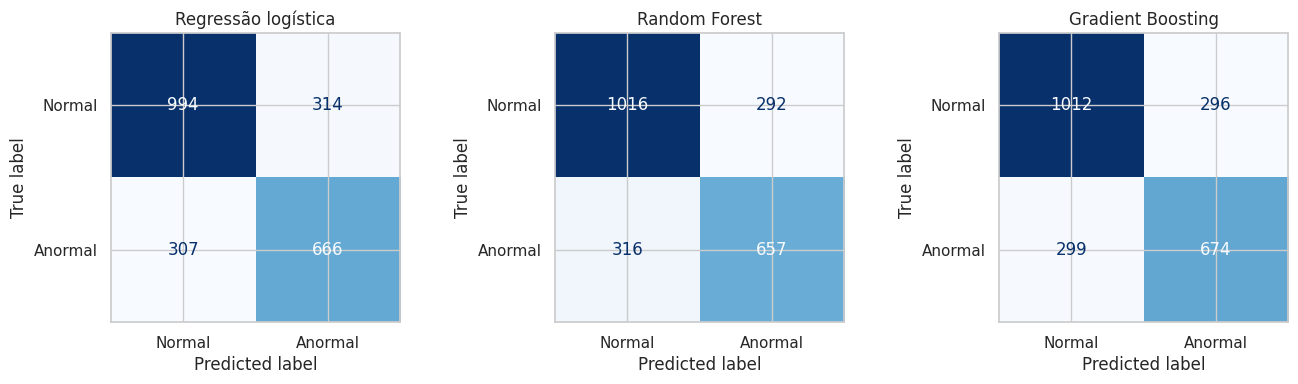

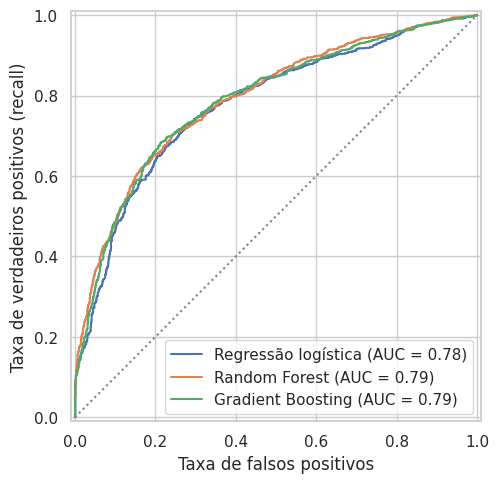

In [ ]:
fig, axes = plt.subplots(1, len(modelos_finais), figsize=(4.5 * len(modelos_finais), 4))
for ax, (nome, pred) in zip(np.atleast_1d(axes), previsoes.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred), display_labels=['Normal', 'Anormal']).plot(
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nome)
plt.tight_layout()
plt.savefig(PASTA + 'fig_matrizes_confusao.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
for nome, prob in probabilidades.items():
    RocCurveDisplay.from_predictions(y_teste, prob, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], ls=':', color='grey')
ax.set_xlabel('Taxa de falsos positivos'); ax.set_ylabel('Taxa de verdadeiros positivos (recall)')
plt.tight_layout()
plt.savefig(PASTA + 'fig_curvas_roc.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.5 Importância dos atributos (variáveis menos importantes)
Importância por permutação no teste: quanto a ROC-AUC cai quando os valores de uma variável são embaralhados.
Variáveis com queda perto de zero (ou negativa) **não contribuem** para o modelo.

,Regressão logística,Random Forest,Gradient Boosting
MOTIVO1,0.1654,0.1712,0.1581
B2,0.0387,0.0363,0.0438
IDADE,0.0018,0.0123,0.0224
HDA_NAO_INFORMADO,0.0209,0.0129,0.0209
FC,0.0122,0.0159,0.0189
HDA_N_SINTOMAS,0.0052,0.0039,0.0070
PA SISTOLICA,0.0033,0.0022,0.0055
Peso,0.0067,0.0008,0.0035
PA DIASTOLICA,0.0001,0.0016,0.0028
SEXO,0.0007,0.0011,0.0021


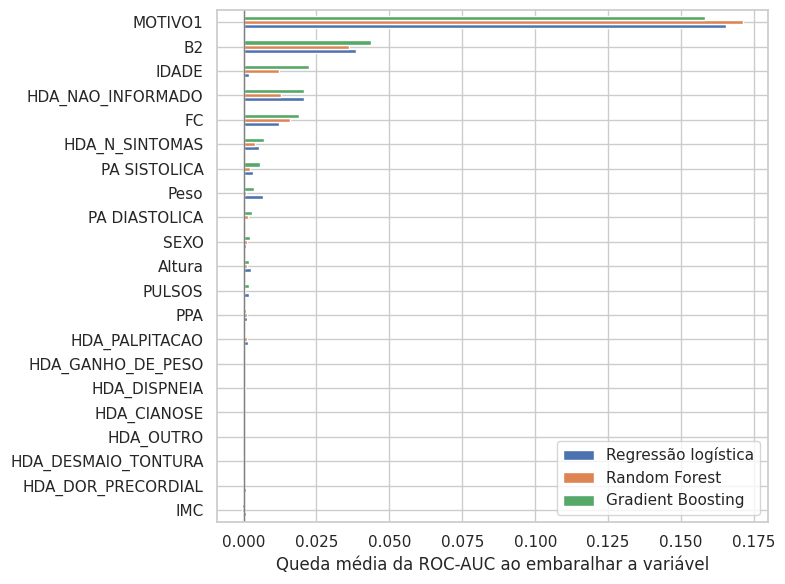

Variáveis com importância desprezível (< 0,005) em todos os modelos:
['PA DIASTOLICA', 'SEXO', 'Altura', 'PULSOS', 'PPA', 'HDA_PALPITACAO', 'HDA_DISPNEIA', 'HDA_OUTRO', 'HDA_GANHO_DE_PESO', 'HDA_CIANOSE', 'HDA_DESMAIO_TONTURA', 'HDA_DOR_PRECORDIAL', 'IMC']


In [ ]:
importancias = {}
for nome, modelo in modelos_finais.items():
    r = permutation_importance(modelo, X_teste, y_teste, scoring='roc_auc',
                               n_repeats=10, random_state=SEED, n_jobs=-1)
    importancias[nome] = pd.Series(r.importances_mean, index=X_teste.columns)
tabela_imp = pd.DataFrame(importancias).sort_values(nomes[-1], ascending=False).round(4)
display(tabela_imp)

tabela_imp.sort_values(nomes[-1]).plot.barh(figsize=(8, 6))
plt.xlabel('Queda média da ROC-AUC ao embaralhar a variável')
plt.axvline(0, color='grey', lw=1)
plt.tight_layout()
plt.savefig(PASTA + 'fig_importancia.png', dpi=300, bbox_inches='tight')
plt.show()

print('Variáveis com importância desprezível (< 0,005) em todos os modelos:')
print(tabela_imp[(tabela_imp < 0.005).all(axis=1)].index.tolist())

7.6 Tabela formatada (média ± dp) para o artigo IEEE e análise clínica de erros

In [ ]:
tabela_cv_formatada = pd.DataFrame({
    m: [f"{tabela_cv.loc[mod, m]:.3f} ± {tabela_cv.loc[mod, m + '_dp']:.3f}" for mod in tabela_cv.index]
    for m in METRICAS
}, index=tabela_cv.index)

print("=== Tabela CV Formatada (copiar p/ LaTeX) ===")
display(tabela_cv_formatada)

# Detalhamento clínico dos erros no conjunto de teste (foco em Falsos Negativos)
erros_clinicos = []
for nome, pred in previsoes.items():
    tn, fp, fn, tp = confusion_matrix(y_teste, pred).ravel()
    erros_clinicos.append({
        'Modelo': nome,
        'Verdadeiros Positivos (Anormal detectado)': tp,
        'Falsos Negativos (Anormal perdido - crítico)': fn,
        'Verdadeiros Negativos (Normal correto)': tn,
        'Falsos Positivos (Alarme falso)': fp,
        'Taxa de Falso Negativo (%)': round(fn / (fn + tp) * 100, 1)
    })
display(pd.DataFrame(erros_clinicos).set_index('Modelo'))

=== Tabela CV Formatada (copiar p/ LaTeX) ===


,recall,precisao,f1,acuracia_bal,roc_auc
Regressão logística,0.654 ± 0.016,0.660 ± 0.022,0.657 ± 0.018,0.702 ± 0.016,0.760 ± 0.016
RF padrão,0.589 ± 0.022,0.688 ± 0.024,0.635 ± 0.021,0.695 ± 0.017,0.762 ± 0.020
Random Forest,0.652 ± 0.020,0.679 ± 0.026,0.665 ± 0.021,0.711 ± 0.018,0.776 ± 0.020
Gradient Boosting,0.662 ± 0.020,0.680 ± 0.025,0.671 ± 0.020,0.715 ± 0.018,0.775 ± 0.019
GB padrão,0.591 ± 0.017,0.716 ± 0.021,0.647 ± 0.017,0.708 ± 0.014,0.775 ± 0.020


,Verdadeiros Positivos (Anormal detectado),Falsos Negativos (Anormal perdido - crítico),Verdadeiros Negativos (Normal correto),Falsos Positivos (Alarme falso),Taxa de Falso Negativo (%)
Modelo,,,,,
Regressão logística,666,307,994,314,31.6
Random Forest,657,316,1016,292,32.5
Gradient Boosting,674,299,1012,296,30.7


7.7 Importância das variáveis focada em RECALL (métrica clínica prioritária) com barras de erro

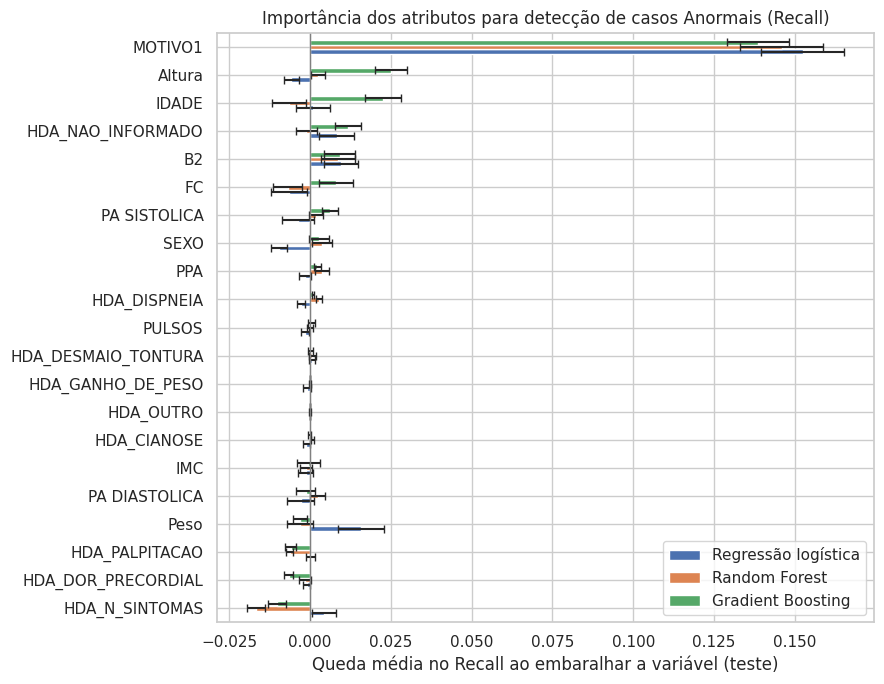

In [ ]:
imp_recall_mean, imp_recall_std = {}, {}
for nome, modelo in modelos_finais.items():
    r = permutation_importance(modelo, X_teste, y_teste, scoring='recall',
                               n_repeats=15, random_state=SEED, n_jobs=-1)
    imp_recall_mean[nome] = pd.Series(r.importances_mean, index=X_teste.columns)
    imp_recall_std[nome] = pd.Series(r.importances_std, index=X_teste.columns)

df_imp_rec = pd.DataFrame(imp_recall_mean).sort_values('Gradient Boosting', ascending=True)
df_err_rec = pd.DataFrame(imp_recall_std).loc[df_imp_rec.index]

ax = df_imp_rec.plot.barh(xerr=df_err_rec, figsize=(9, 7), capsize=3)
plt.xlabel('Queda média no Recall ao embaralhar a variável (teste)')
plt.title('Importância dos atributos para detecção de casos Anormais (Recall)')
plt.axvline(0, color='grey', lw=1)
plt.tight_layout()
plt.savefig(PASTA + 'fig_importancia_recall.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Anotações para o artigo
- Resultados da validação cruzada: tabela da seção 7.1 (média ± desvio padrão).
- Resultados no teste: tabela da seção 7.2 + McNemar (7.3).
- Figuras salvas: fig_coeficientes_lr.png, fig_matrizes_confusao.png fig_curvas_roc.png, fig_importancia.png, fig_importancia_recall.png.
- Discutir: vazamento do Sopro (e do MOTIVO2), falsos negativos, variáveis pouco importantes e comparação com a bivariada da A1.